# Métricas no supervisadas para la optimización de hiperparámetros en detectores de anomalías IoT en el borde
Belén Aedo Peña.

En este cuaderno muestro el experimento completo, desde los datos hasta los resultados, en el mismo orden del
Capítulo 3 de la memoria. Debajo de cada tabla y figura dejé una línea que empieza con *Fuente*: ahí indico de qué
archivo sale, qué script la generó y con qué parámetros de la configuración. La idea es que cualquier número de la
memoria se pueda rastrear hasta aquí.

El cuaderno no vuelve a correr las etapas largas (la búsqueda de hiperparámetros toma varias horas). Lo que hace es
leer lo que guardó el pipeline, revisar que se pueda reproducir y presentarlo. Si un resultado todavía no existe, la
celda lo dice y el cuaderno sigue con la siguiente. La explicación de cada función del código, con ejemplos
pequeños, está en `cuaderno_funciones.ipynb`.

## Cómo lo ejecuto
```powershell
cd tesis_hpo_edge
.\.venv\Scripts\Activate.ps1                          # Python 3.10
pip install -r requirements.txt
python run_all.py --config config/experiment_v2.yaml  # todo el pipeline de la versión 2
```
Después abro este cuaderno en VS Code, elijo el kernel `.venv` (Python 3.10) y uso *Run All*. Tarda alrededor de
un minuto. Tiene que ser ese entorno: los modelos se entrenaron con sus versiones de bibliotecas, y si aparece
`ModuleNotFoundError` es porque el cuaderno quedó abierto con otro entorno.

En la primera celda de código hay cuatro opciones:
- `CONFIG`: qué versión del experimento se muestra. Por defecto es la versión 2 (`config/experiment_v2.yaml`).
  Con `None` se ve la versión 1, que dejé guardada para poder comparar.
- `VERIFICAR = True`: vuelve a generar las particiones en una carpeta temporal y compara sus hashes con los
  guardados. Tarda unos segundos y no usa etiquetas.
- `VERIFICAR_EVALUACION = False`: si lo activo, vuelve a evaluar los modelos de la semilla 42 en `test_final` y
  compara con lo guardado. Lo dejo apagado porque `test_final` solo debería abrirse para evaluar configuraciones ya
  elegidas. Esta comprobación no elige nada, pero prefiero que abrirlo sea una decisión explícita.
- `REPETIR_UNA_BUSQUEDA = False`: si lo activo, repite una búsqueda completa de Optuna (unos 2 minutos) para ver
  cuánto se parece a la guardada.

## Versión 1 y versión 2
Corrí el experimento dos veces. En la primera (v1) usé el preprocesador tal como venía. Al revisar los datos me di
cuenta de que en TON_IoT más de la mitad de las filas son copias de otras, y que copias del mismo flujo quedaban a
la vez en entrenamiento y en prueba (lo muestro en la sección 4). Para la v2 corregí el preprocesador y volví a
correr todo, dejando el resto de la configuración igual para que la comparación sea limpia. Los resultados de la
memoria son los de la v2. La v1 queda en `data/splits` y `outputs/`; la v2, en `data/splits_v2` y `outputs_v2/`.

## Qué parte del código hace cada cosa
El cuaderno no reimplementa nada: importa los módulos de `src/` y llama a sus funciones. Los scripts numerados
(`1_prepare_splits.py`, etc.) los cargo con `importlib.import_module`, porque Python no permite escribir `import`
con un nombre que empieza con un número.

| Etapa | Memoria | Script o módulo | Funciones principales | Qué archivos produce |
|---|---|---|---|---|
| Datos y preprocesamiento | 3.1.3, 3.1.4 | `preprocessor/`, llamado desde `run_all.py` | `etapa_preprocesar` | `Datasets/Parquet/Ton-IoT-v2/*_processed.parquet` |
| Particiones y variables | 3.2.2, 3.2.3 | `src/1_prepare_splits.py` | `select_unsupervised`, `fit_scaler`, `stratified_halves` | `data/splits_v2/*`, `manifest.json` |
| Detectores y umbral | 3.2.4, 3.2.5 | `src/detectors.py`, `src/search_space.py` | `IForestDetector`, `LOFDetector`, `AutoencoderDetector`, `set_threshold`, `suggest_params` | |
| Funciones objetivo | 3.2.6 | `src/objectives.py` | `compute_objective` | |
| Diagnóstico | 3.2.10 | `src/2_diagnose.py` | `main` | `outputs_v2/results/diagnose_objectives*` |
| Búsqueda | 3.2.7, 3.2.8 (etapa 1) | `src/3_optimize.py` | `run_study`, `build_baseline` | `outputs_v2/optuna/*.json`, `outputs_v2/models/*.pkl` |
| Medición en el borde | 3.2.8 (etapa 2) | `src/4_edge_benchmark.py` | `worker`, `meets` | `outputs_v2/results/edge_benchmark.csv` |
| Evaluación final | 3.2.9 | `src/5_evaluate.py` | `select_entries`, `evaluate_entry`, `summarize`, `pareto_front` | `outputs_v2/results/*.csv`, `hypothesis_check.json` |
| Tablas LaTeX | | `src/6_report.py` | `table_*` | `outputs_v2/tables/*.tex` |

In [1]:
CONFIG = "config/experiment_v2.yaml"   # None = versión 1 (config/experiment.yaml)
VERIFICAR = True                       # regenera las particiones y compara hashes (~5 s, sin etiquetas)
VERIFICAR_EVALUACION = False           # reevalúa la semilla 42 en test_final (abre sus etiquetas)
REPETIR_UNA_BUSQUEDA = False           # repite iforest + silhouette, semilla 42, 100 intentos (~2 min)

import hashlib, importlib, json, platform, subprocess, sys, tempfile, warnings
from datetime import datetime
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))

import common, detectors, objectives, search_space            # módulos de apoyo
ps  = importlib.import_module("1_prepare_splits")             # scripts numerados
opt = importlib.import_module("3_optimize")
ev  = importlib.import_module("5_evaluate")

cfg = common.load_config(RAIZ / CONFIG if CONFIG else None)   # config/experiment.yaml (+ CONFIG encima)
VERSION = "v2" if CONFIG else "v1"
OUT = common.outputs_dir(cfg)
RES, MOD, SPL = common.results_dir(cfg), common.models_dir(cfg), common.splits_dir(cfg)
print(f"Versión {VERSION} | configuración: {CONFIG or 'config/experiment.yaml'} | dataset: {cfg['dataset']['name']} | salidas: {OUT.relative_to(RAIZ)}")

def sha(p, n=12):
    return common.sha256_of(p)[:n]

def fuente(archivo, codigo, params=""):
    """Imprime de dónde sale una tabla o figura: archivo (con huella y fecha), código y parámetros."""
    p = Path(archivo)
    fecha = datetime.fromtimestamp(p.stat().st_mtime).strftime("%Y-%m-%d %H:%M") if p.exists() else "NO EXISTE"
    huella = sha(p) if p.exists() and p.is_file() else "-"
    print(f"Fuente: {p.relative_to(RAIZ)} (sha256 {huella}…, {fecha}) | código: {codigo}" + (f" | config: {params}" if params else ""))

def hay(*rutas, que=""):
    """True si existen todos los archivos; si falta alguno, avisa que ese resultado está pendiente."""
    faltan = [Path(p) for p in rutas if not Path(p).exists()]
    if faltan:
        print(f"Pendiente{': ' + que if que else ''}. Todavía no existe: " + ", ".join(str(p.relative_to(RAIZ)) for p in faltan))
    return not faltan

Versión v2 | configuración: config/experiment_v2.yaml | dataset: Ton-IoT-v2 | salidas: outputs_v2


---
# 1. Versión del código, entorno, configuración, semillas y datos
*(Memoria 3.1.1, 3.1.2 y 3.2.11)*

Lo primero es dejar anotado con qué se generó todo lo que viene después. Para repetir el experimento hace falta el
mismo código, la misma configuración, las mismas semillas y versiones compatibles de las bibliotecas. Las versiones
importan más de lo que parece: los modelos se guardan con `pickle`, y la Raspberry Pi tiene que cargarlos con la
misma versión de scikit-learn con que se entrenaron.

### Versión del código
Para identificar exactamente qué código produjo los resultados, calculo la huella SHA-256 de cada archivo que
participa en el experimento: los scripts de `src/`, `run_all.py`, la configuración y las etapas del preprocesador
que uso. La última línea es una huella única de todo el conjunto: si cualquier archivo cambia, cambia también.

In [2]:
archivos_codigo = (sorted((RAIZ / "src").glob("*.py")) + [RAIZ / "run_all.py", RAIZ / "requirements.txt"]
                   + sorted((RAIZ / "config").glob("*.yaml")) + [RAIZ / "preprocessor/config.json"]
                   + sorted((RAIZ / "preprocessor/preprocessor_v2").glob("0[0-2]_*/*.py"))
                   + sorted((RAIZ / "preprocessor/preprocessor_v2").glob("0[0-2]_*.py")))
version = pd.DataFrame([{"archivo": str(f.relative_to(RAIZ)), "sha256": common.sha256_of(f)[:16] + "…",
                         "modificado": datetime.fromtimestamp(f.stat().st_mtime).strftime("%Y-%m-%d %H:%M")}
                        for f in archivos_codigo if f.exists()])
display(version)
total = hashlib.sha256("".join(common.sha256_of(RAIZ / a) for a in version.archivo).encode()).hexdigest()
print(f"Huella del código completo ({len(version)} archivos): {total[:16]}")

,archivo,sha256,modificado
0,src\1_prepare_splits.py,a675575c7539616d…,2026-11-13 18:08
1,src\2_diagnose.py,f7f9c0e2427a1982…,2026-11-11 08:13
2,src\3_optimize.py,30bf0ad1d46a93d6…,2026-11-13 18:08
3,src\4_edge_benchmark.py,a1a1fcb419c469fb…,2026-11-11 08:13
4,src\5_evaluate.py,1ef7d52ca59dfd2f…,2026-11-11 08:13
5,src\6_report.py,fcecd9013b9badc2…,2026-11-11 08:13
6,src\common.py,0d8cf5cfde00b1cc…,2026-11-11 08:13
7,src\detectors.py,e988a5aed2b7767f…,2026-11-11 08:13
8,src\objectives.py,16b8bf6afb7a5bae…,2026-11-11 08:13
9,src\search_space.py,c26a8cd769526643…,2026-11-11 08:13


Huella del código completo (27 archivos): 9eb49859946983e1


### Entorno
Comparo las versiones de esta sesión con las que quedaron registradas cuando se entrenaron los modelos (`env.json`).

In [3]:
import sklearn, scipy, optuna, pyarrow, psutil
ahora = {"python": platform.python_version(), "numpy": np.__version__, "scikit-learn": sklearn.__version__,
         "scipy": scipy.__version__, "pandas": pd.__version__, "optuna": optuna.__version__,
         "pyarrow": pyarrow.__version__, "psutil": psutil.__version__, "platform": platform.platform()}
entreno = common.load_json(MOD / "env.json") if (MOD / "env.json").exists() else {}
tabla = pd.DataFrame({"esta ejecución": ahora, "entrenamiento de los modelos": entreno}).fillna("-")
tabla["¿igual?"] = [("sí" if str(a) == str(b) else ("-" if b == "-" else "NO")) for a, b in zip(tabla.iloc[:, 0], tabla.iloc[:, 1])]
display(tabla)
fuente(MOD / "env.json", "3_optimize.write_env")

,esta ejecución,entrenamiento de los modelos,¿igual?
python,3.10.11,3.10.11,sí
numpy,2.2.6,2.2.6,sí
scikit-learn,1.7.2,1.7.2,sí
scipy,1.15.3,1.15.3,sí
pandas,2.3.3,-,-
optuna,5.0.0,-,-
pyarrow,25.0.1,-,-
psutil,7.2.2,-,-
platform,Windows-10-10.0.26200-SP0,Windows-10-10.0.26100-SP0,NO
tensorflow,-,-,sí


Fuente: outputs_v2\models\env.json (sha256 21af5dd7da53…, 2026-11-13 18:43) | código: 3_optimize.write_env


### Configuración
Todos los parámetros salen de `config/experiment.yaml`. La v2 solo cambia lo que está en
`config/experiment_v2.yaml`: las carpetas de salida y el nombre del dataset del preprocesador. Imprimo la huella
SHA-256 de los dos archivos para que quede claro exactamente cuál usé, y abajo los parámetros que más importan.

In [4]:
p = RAIZ / "config" / "experiment.yaml"
print("SHA-256 de config/experiment.yaml:", common.sha256_of(p))
if CONFIG: print(f"SHA-256 de {CONFIG}:", common.sha256_of(RAIZ / CONFIG))
clave = {
    "dataset.name": cfg["dataset"]["name"], "input.variant": cfg["input"]["variant"], "features.mode": cfg["features"]["mode"],
    "features.max_features": cfg["features"]["max_features"], "features.min_minority_freq": cfg["features"]["min_minority_freq"],
    "features.max_abs_corr": cfg["features"]["max_abs_corr"], "scaling": f"{cfg['scaling']['method']} (clip ±{cfg['scaling']['clip']})",
    "split.val_frac_of_normal": cfg["split"]["val_frac_of_normal"], "split.oracle_frac_of_test": cfg["split"]["oracle_frac_of_test"],
    "threshold.q": cfg["threshold"]["q"], "threshold.calib_frac": cfg["threshold"]["calib_frac"],
    "threshold.sensitivity_q": cfg["threshold"]["sensitivity_q"], "detectors": cfg["detectors"],
    "optimization.n_trials": cfg["optimization"]["n_trials"], "optimization.seeds": cfg["optimization"]["seeds"],
    "optimization.top_k": cfg["optimization"]["top_k"], "optimization.max_train_rows": cfg["optimization"]["max_train_rows"],
    "edge.max_latency_ms / dev_slowdown_factor": f"{cfg['edge']['max_latency_ms']} / {cfg['edge']['dev_slowdown_factor']}",
    "edge.max_cpu_percent @ flow_rate_per_s": f"{cfg['edge']['max_cpu_percent']} % @ {cfg['edge']['flow_rate_per_s']}/s",
    "edge.max_ram_mb / max_model_kb": f"{cfg['edge']['max_ram_mb']} / {cfg['edge']['max_model_kb']}",
}
pd.Series(clave, name="valor").to_frame()

SHA-256 de config/experiment.yaml: 90826f07ff50c0ad30e1e366224e875c69691f26237b39eecbb686bdea000be8
SHA-256 de config/experiment_v2.yaml: d87639a3b8cf311889b066c9f47236806ab4ec9fb13794488b23d67a8206e903


,valor
dataset.name,Ton-IoT-v2
input.variant,processed
features.mode,unsupervised
features.max_features,40
features.min_minority_freq,0.001
features.max_abs_corr,0.95
scaling,standard (clip ±10.0)
split.val_frac_of_normal,0.15
split.oracle_frac_of_test,0.5
threshold.q,0.95


### Semillas
Hay azar en varios lugares del experimento y fijé una semilla en cada uno:

| Semilla | Valor | Dónde se fija | Para qué |
|---|---|---|---|
| `split.seed` (config) | 42 | `1_prepare_splits.main`, `common.split_val` | partir train/val, test_oracle/test_final y la validación en calibración/objetivo |
| `split_seed` (preprocesador v2) | 42 | `preprocessor/config.json`, etapa 01 | partición 80/20 estratificada del preprocesador |
| `optimization.seeds` (config) | 42, 43, 44, 45, 46 | `3_optimize.run_study` | semilla de TPE (`TPESampler(seed)`), de `random`/`numpy` y de cada detector (`random_state`) |
| fija en el código | 42 | `common.subsample` | submuestra de 10 000 filas del entrenamiento |
| `split.seed` | 42 | `1_prepare_splits.select_unsupervised` | muestra de 20 000 filas para calcular correlaciones |
| fija en el código | 0 | `objectives.objective_silhouette` | muestra de 5 000 filas para Silhouette |
| fija en el código | 42 | `objectives.objective_stability`, `objective_consistency` | ruido de la estabilidad y submuestras de la consistencia |
| fija en el código | 42 | `4_edge_benchmark.worker` | filas que se usan para medir en la Raspberry Pi |
| `2_diagnose.py --seed` | 0 | `2_diagnose.main` | configuraciones al azar del diagnóstico |

### Datos de entrada
El archivo original de TON_IoT y lo que sale del preprocesador, con su tamaño y su huella.

In [5]:
csv = RAIZ / "Datasets/Sources/TON-IoT/Train_Test_datasets/Train_Test_Network_dataset/Train_Test_Labels.csv"
pq_dir = common.datasets_dir(cfg) / "Parquet" / cfg["dataset"]["name"]
filas = []
for f in [csv] + sorted(pq_dir.glob("*_processed.parquet")):
    if f.exists():
        filas.append({"archivo": str(f.relative_to(RAIZ)), "MB": round(f.stat().st_size / 1e6, 1), "sha256": common.sha256_of(f)[:16] + "…"})
display(pd.DataFrame(filas))
print("Train_Test_Labels.csv es una copia sin modificar de Train_Test_Network.csv (la crea run_all.etapa_preprocesar).")
print("Preprocesador: preprocessor/preprocessor_v2.")
print("En la v2 está modificado (sección 3)." if VERSION == "v2" else "En la v1 solo cambié rutas en config.yaml/config.json (scripts/0_configurar_preprocessor.py).")

,archivo,MB,sha256
0,Datasets\Sources\TON-IoT\Train_Test_datasets\T...,29.9,26ddc513552de36d…
1,Datasets\Parquet\Ton-IoT-v2\test_processed.par...,0.5,e616ed8d6508d95d…
2,Datasets\Parquet\Ton-IoT-v2\train_processed.pa...,1.7,75cade4421c18aad…


Train_Test_Labels.csv es una copia sin modificar de Train_Test_Network.csv (la crea run_all.etapa_preprocesar).
Preprocesador: preprocessor/preprocessor_v2.
En la v2 está modificado (sección 3).


---
# 2. Qué resultados ya están y cuáles faltan

In [6]:
etapas = [
    ("Preprocesamiento (etapas 00-02)", pq_dir / "train_processed.parquet", "3.1.3"),
    ("Particiones", SPL / "manifest.json", "3.2.3"),
    ("Diagnóstico de las funciones objetivo", RES / "diagnose_objectives_summary.json", "3.2.10"),
    ("Búsqueda con Optuna", OUT / "optuna/all_studies.json", "3.2.7"),
    ("Medición en la Raspberry Pi 5", RES / "edge_benchmark.csv", "3.2.8 etapa 2"),
    ("Evaluación final", RES / "final_evaluation.csv", "3.2.9"),
    ("Frente de Pareto MCC/latencia", RES / "pareto_mcc_latencia.csv", "3.2.8"),
    ("Tablas LaTeX", OUT / "tables/tab_mock_balance.tex", "-"),
]
estado = pd.DataFrame([{"etapa": e, "memoria": s, "archivo": str(f.relative_to(RAIZ)),
                        "estado": "DISPONIBLE" if f.exists() else "PENDIENTE",
                        "fecha": datetime.fromtimestamp(f.stat().st_mtime).strftime("%Y-%m-%d %H:%M") if f.exists() else "-"}
                       for e, f, s in etapas])
n_busq = len(list((OUT / "optuna").glob("*_seed*.json")))
display(estado)
print(f"Búsquedas terminadas: {n_busq} de 60")

,etapa,memoria,archivo,estado,fecha
0,Preprocesamiento (etapas 00-02),3.1.3,Datasets\Parquet\Ton-IoT-v2\train_processed.pa...,DISPONIBLE,2026-11-13 18:09
1,Particiones,3.2.3,data\splits_v2\manifest.json,DISPONIBLE,2026-11-13 18:09
2,Diagnóstico de las funciones objetivo,3.2.10,outputs_v2\results\diagnose_objectives_summary...,DISPONIBLE,2026-11-13 18:43
3,Búsqueda con Optuna,3.2.7,outputs_v2\optuna\all_studies.json,PENDIENTE,-
4,Medición en la Raspberry Pi 5,3.2.8 etapa 2,outputs_v2\results\edge_benchmark.csv,PENDIENTE,-
5,Evaluación final,3.2.9,outputs_v2\results\final_evaluation.csv,PENDIENTE,-
6,Frente de Pareto MCC/latencia,3.2.8,outputs_v2\results\pareto_mcc_latencia.csv,PENDIENTE,-
7,Tablas LaTeX,-,outputs_v2\tables\tab_mock_balance.tex,PENDIENTE,-


Búsquedas terminadas: 31 de 60


Algunas notas sobre esta tabla (13-11-2026):
- La corrida completa de la v2 empezó el 13-11-2026 y todavía no termina. Las celdas cuyos archivos no existen
  dicen *Pendiente* y no muestran nada; cuando termine, basta con volver a ejecutar el cuaderno.
- La medición en la Raspberry Pi 5 está pendiente en las dos versiones. Mientras no exista,
  `5_evaluate.select_entries` toma la configuración de rango 0 de cada búsqueda, sin el filtro de latencia, CPU y
  RAM de la etapa 2, y el frente de Pareto usa la latencia mediana medida en el PC. Por eso considero provisionales
  esos resultados.
- Con la v1 comprobé que la evaluación es reproducible: la regeneré con el código actual y dio exactamente las
  mismas métricas.

---
# 3. Los datos y el preprocesamiento *(Memoria 1.5.3, 3.1.3 y 3.1.4)*

Uso el archivo `Train_Test_Network.csv` de TON_IoT completo (`input.variant: processed`) y lo paso por las etapas
00 a 02 del preprocesador. No uso la etapa 03, que saca una muestra del 10 % y solo me sirvió para pruebas rápidas,
ni la etapa 04, porque elige variables usando las etiquetas y eso no calza con un enfoque no supervisado.

Para la v2 hice estos cambios al preprocesador:
- La etapa 01 elimina los flujos repetidos antes de partir en entrenamiento y prueba. También elimina los 13 flujos
  distintos que aparecen a la vez con etiqueta normal y de ataque (7 122 filas en total), porque no hay forma de
  saber cuál etiqueta es la correcta.
- La partición 80/20 de la etapa 01 queda estratificada por tipo de ataque.
- La etapa 02 aplica log(1+x) a las 10 variables numéricas antes del MinMax. Bytes, paquetes y duración tienen
  colas muy largas, y sin el logaritmo casi todos los flujos quedaban apretados cerca de cero.
- El one-hot se arma con todas las categorías del entrenamiento y no solo con las de las primeras 10 000 filas.
- Los campos de texto que dependen del entorno donde se capturó el tráfico (`dns_query`, `http_uri`,
  `http_user_agent`, `ssl_subject`, `ssl_issuer`) pasan a ser identificadores y no variables. Un detector que
  aprende esos valores aprende el laboratorio, no el comportamiento del tráfico.
- Corregí la etapa 00, que en algunos casos leía su propio archivo de salida en vez del CSV original.

In [7]:
cols = ["label", "type"]
raw = pd.read_csv(csv, usecols=cols)
t = raw["type"].value_counts().rename("flujos").to_frame()
t["%"] = (100 * t["flujos"] / len(raw)).round(1)
print(f"Train_Test_Network.csv: {len(raw):,} flujos | normal {int((raw.label == 0).sum()):,} | ataque {int((raw.label == 1).sum()):,} ({raw.label.mean():.1%})")
display(t.T)
fuente(csv, "lectura directa del CSV original")

Train_Test_Network.csv: 211,043 flujos | normal 50,000 | ataque 161,043 (76.3%)


type,normal,backdoor,ddos,dos,injection,password,scanning,ransomware,xss,mitm
flujos,50000.0,20000.0,20000.0,20000.0,20000.0,20000.0,20000.0,20000.0,20000.0,1043.0
%,23.7,9.5,9.5,9.5,9.5,9.5,9.5,9.5,9.5,0.5


Fuente: Datasets\Sources\TON-IoT\Train_Test_datasets\Train_Test_Network_dataset\Train_Test_Labels.csv (sha256 26ddc513552d…, 2026-10-10 12:27) | código: lectura directa del CSV original


In [8]:
if hay(pq_dir / "train_processed.parquet", pq_dir / "test_processed.parquet", que="salida del preprocesador"):
    tr = pd.read_parquet(pq_dir / "train_processed.parquet")
    te = pd.read_parquet(pq_dir / "test_processed.parquet", columns=["category"])
    variables = [c for c in tr.columns if c not in ("category", "label", "type")]
    binarias = [c for c in variables if tr[c].dropna().isin([0, 1]).all()]
    print(f"Salida del preprocesador ({VERSION}): train {len(tr):,} filas, test {len(te):,} filas, {len(tr) + len(te):,} en total")
    print(f"  train: normal {int((tr.category == 0).sum()):,}, ataque {int((tr.category == 1).sum()):,}")
    print(f"  test:  normal {int((te.category == 0).sum()):,}, ataque {int((te.category == 1).sum()):,} ({(te.category == 1).mean():.1%} de ataques)")
    print(f"  {len(variables)} columnas de variables: {len(variables) - len(binarias)} numéricas y {len(binarias)} binarias")
    fuente(pq_dir / "train_processed.parquet", "preprocessor/preprocessor_v2/01_train_test_split.py + 02_preprocessing.py")

Salida del preprocesador (v2): train 74,764 filas, test 18,691 filas, 93,455 en total
  train: normal 18,926, ataque 55,838
  test:  normal 4,732, ataque 13,959 (74.7% de ataques)
  136 columnas de variables: 10 numéricas y 126 binarias
Fuente: Datasets\Parquet\Ton-IoT-v2\train_processed.parquet (sha256 75cade4421c1…, 2026-11-13 18:09) | código: preprocessor/preprocessor_v2/01_train_test_split.py + 02_preprocessing.py


---
# 4. Selección de variables y particiones *(Memoria 3.2.2 y 3.2.3, Tablas 3.2 a 3.4)*

Estas son las decisiones de esta parte, en resumen. En `cuaderno_funciones.ipynb` (partes 2 y 3) las explico con
ejemplos.
- Entreno y valido solo con tráfico normal. Es el esquema *one-class* del alcance (1.4.3): en una red real casi
  nunca se sabe qué es ataque, pero sí se puede juntar un período de tráfico normal. Los ataques que el
  preprocesador deja en el entrenamiento los descarto.
- Me quedo con 40 variables como máximo y las elijo sin mirar etiquetas: saco las constantes y las binarias que
  casi nunca valen 1, priorizo las numéricas y, de cada par con correlación |r| ≥ 0,95, dejo una sola. Menos
  variables significa menos cálculo por flujo en el dispositivo.
- Estandarizo con la media y la desviación del entrenamiento normal y recorto a ±10. Las binarias no las toco.
- Parto la validación en dos mitades: con la de calibración fijo el umbral y con la otra calculo la función
  objetivo. Así el umbral y la métrica no salen de las mismas filas.
- Parto la prueba en dos mitades estratificadas por tipo de ataque. El escenario oráculo optimiza con una
  (`test_oracle`) y todos los escenarios se evalúan en la otra (`test_final`), que abro una sola vez y cuyo hash
  reviso antes de abrirla.

In [9]:
if hay(SPL / "features.json", SPL / "scaler.json", que="selección de variables"):
    fj = common.load_json(SPL / "features.json")
    s = fj["stats"]
    print(f"Variables: {s['columnas_entrada']} de entrada -> {s['constantes']} constantes, {s['binarias_raras']} binarias raras, "
          f"{s['descartadas_por_correlacion']} descartadas por correlación -> {s['conservadas']} conservadas "
          f"({s['conservadas_numericas']} numéricas + {s['conservadas_binarias']} binarias)")
    sc = common.load_json(SPL / "scaler.json")
    print("Numéricas conservadas:", [c for c, b in zip(sc["columns"], sc["binary"]) if not b])
    fuente(SPL / "features.json", "1_prepare_splits.select_unsupervised",
           f"max_features={cfg['features']['max_features']}, min_minority_freq={cfg['features']['min_minority_freq']}, max_abs_corr={cfg['features']['max_abs_corr']}")

Variables: 136 de entrada -> 16 constantes, 54 binarias raras, 20 descartadas por correlación -> 40 conservadas (9 numéricas + 31 binarias)
Numéricas conservadas: ['duration', 'src_bytes', 'dst_bytes', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'http_request_body_len', 'http_response_body_len']
Fuente: data\splits_v2\features.json (sha256 a1d1550c029d…, 2026-11-13 18:09) | código: 1_prepare_splits.select_unsupervised | config: max_features=40, min_minority_freq=0.001, max_abs_corr=0.95


### Tabla 3.3: tamaño de cada bloque (sale del manifiesto)

In [10]:
man = common.load_json(SPL / "manifest.json"); sp = man["splits"]
n_val = sp["val"]["rows"]; n_cal = int(round(cfg["threshold"]["calib_frac"] * n_val))
filas = [("Entrenamiento", sp["train"]["rows"], sp["train"]["rows"], 0), ("Validación", n_val, n_val, 0),
         ("  calibración", n_cal, n_cal, 0), ("  objetivo", n_val - n_cal, n_val - n_cal, 0),
         ("Prueba: oráculo", sp["test_oracle"]["rows"], sp["test_oracle"]["normal"], sp["test_oracle"]["attack"]),
         ("Prueba: final", sp["test_final"]["rows"], sp["test_final"]["normal"], sp["test_final"]["attack"])]
t33 = pd.DataFrame(filas, columns=["Bloque", "Filas", "Normal", "Ataque"]).set_index("Bloque")
t33["% ataque"] = (100 * t33["Ataque"] / t33["Filas"]).round(1)
display(t33)
fuente(SPL / "manifest.json", "1_prepare_splits.main + common.split_val",
       f"split.seed={man['seed']}, val_frac_of_normal={cfg['split']['val_frac_of_normal']}, oracle_frac_of_test={cfg['split']['oracle_frac_of_test']}, calib_frac={cfg['threshold']['calib_frac']}")

,Filas,Normal,Ataque,% ataque
Bloque,,,,
Entrenamiento,16087,16087,0,0.0
Validación,2839,2839,0,0.0
calibración,1420,1420,0,0.0
objetivo,1419,1419,0,0.0
Prueba: oráculo,9343,2366,6977,74.7
Prueba: final,9348,2366,6982,74.7


Fuente: data\splits_v2\manifest.json (sha256 7c9afb16fb60…, 2026-11-13 18:09) | código: 1_prepare_splits.main + common.split_val | config: split.seed=42, val_frac_of_normal=0.15, oracle_frac_of_test=0.5, calib_frac=0.5


### Tabla 3.4: tipos de ataque en cada mitad de la prueba

,backdoor,ddos,dos,injection,mitm,password,ransomware,scanning,xss
Oráculo,196,1195,644,1978,103,1524,25,447,865
Final,197,1195,645,1978,104,1525,25,448,865


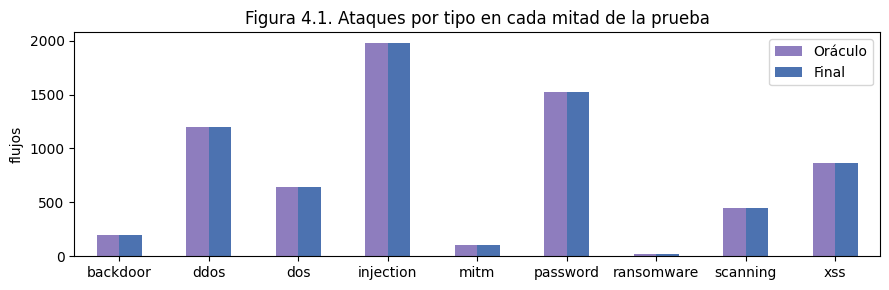

Fuente: data\splits_v2\manifest.json (sha256 7c9afb16fb60…, 2026-11-13 18:09) | código: 1_prepare_splits.stratified_halves


In [11]:
t34 = pd.DataFrame({"Oráculo": sp["test_oracle"]["attack_types"], "Final": sp["test_final"]["attack_types"]})
display(t34.T)
fig, ax = plt.subplots(figsize=(9, 3))
t34.plot.bar(ax=ax, color=["#8E7DBE", "#4C72B0"]); ax.set_ylabel("flujos"); ax.set_title("Figura 4.1. Ataques por tipo en cada mitad de la prueba")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
fuente(SPL / "manifest.json", "1_prepare_splits.stratified_halves")

### ¿Las particiones se pueden reproducir?
Vuelvo a correr `1_prepare_splits.py` con el mismo código y la misma configuración, pero hacia una carpeta
temporal, y comparo los hashes SHA-256 con los del manifiesto. Si coinciden, los archivos son idénticos byte a byte.

In [12]:
if VERIFICAR:
    tmp = Path(tempfile.mkdtemp(prefix="verif_"))
    over = {"paths": {"splits_dir": str(tmp / "splits"), "outputs_dir": str(tmp / "out")}, "dataset": {"name": cfg["dataset"]["name"]}}
    cfg_tmp = tmp / "v.yaml"; cfg_tmp.write_text(yaml.safe_dump(over))
    viejo = sys.argv; sys.argv = ["1_prepare_splits.py", "--config", str(cfg_tmp)]
    try:
        import contextlib, io
        with contextlib.redirect_stdout(io.StringIO()): ps.main()
    finally: sys.argv = viejo
    nuevo = common.load_json(tmp / "splits" / "manifest.json")["sha256"]
    display(pd.DataFrame({"guardado": {k: v[:16] for k, v in man["sha256"].items()},
                          "regenerado": {k: v[:16] for k, v in nuevo.items()},
                          "¿idéntico?": {k: man["sha256"][k] == nuevo[k] for k in man["sha256"]}}))
else:
    print("VERIFICAR = False: me salto esta comprobación.")

,guardado,regenerado,¿idéntico?
train,934a2da8881a4c77,934a2da8881a4c77,True
val,362e8cab4d61cf51,362e8cab4d61cf51,True
test_oracle,39c56ef7bcfc6a3a,39c56ef7bcfc6a3a,True
test_final,80c58c52e18f2b62,80c58c52e18f2b62,True


### Flujos repetidos entre bloques: v1 contra v2
Este es el problema que me llevó a correr la v2. En la v1 la etapa 01 partía al azar sin quitar las filas
repetidas, así que copias idénticas de un mismo flujo terminaban en entrenamiento y en prueba. El detector se
evaluaba, en parte, con flujos que ya había visto. La tabla muestra, para cada versión, qué proporción de las filas
de un bloque es idéntica a alguna fila de otro bloque.

In [13]:
def repetidos(carpeta):
    leer = lambda n: common.read_table(common.find_table(carpeta / n))
    Tr, Va, To, Tf = leer("train"), leer("val"), leer("test_oracle"), leer("test_final")
    F = [c for c in Tr.columns if c != "y_true"]
    h = lambda d: pd.util.hash_pandas_object(d[F], index=False)
    hTr = h(Tr); conj_tr, conj_to = set(hTr), set(h(To))
    nf = (Tf.y_true == 0).to_numpy()
    return {"filas únicas en train": hTr.nunique() / len(hTr),
            "val idéntico a alguna fila de train": h(Va).isin(conj_tr).mean(),
            "normales de test_final idénticos a train": h(Tf)[nf].isin(conj_tr).mean(),
            "test_final idéntico a test_oracle": h(Tf).isin(conj_to).mean()}

versiones = {"v1 (data/splits)": RAIZ / "data/splits", "v2 (data/splits_v2)": RAIZ / "data/splits_v2"}
rep = pd.DataFrame({k: repetidos(p) for k, p in versiones.items() if (p / "manifest.json").exists()})
display(rep.apply(lambda s: s.map("{:.1%}".format)))
fuente(SPL / "manifest.json", "comparación de huellas de filas (pandas.util.hash_pandas_object)")

,v1 (data/splits),v2 (data/splits_v2)
filas únicas en train,49.1%,99.9%
val idéntico a alguna fila de train,55.1%,0.5%
normales de test_final idénticos a train,56.0%,0.2%
test_final idéntico a test_oracle,52.0%,0.1%


Fuente: data\splits_v2\manifest.json (sha256 7c9afb16fb60…, 2026-11-13 18:09) | código: comparación de huellas de filas (pandas.util.hash_pandas_object)


En la v1, más de la mitad de la validación y de los normales de `test_final` eran copias exactas de filas del
entrenamiento. En la v2 casi no quedan (lo que queda son flujos distintos en el CSV original que, después de
escalar y elegir variables, quedaron iguales). Además, en la v1 vi que la tasa de falsas alarmas era 0 % en los
normales repetidos y 10,6 % en los nuevos: los repetidos hacían que el detector se viera mejor de lo que es.

---
# 5. Entrenamiento de los detectores *(Memoria 3.2.4 y 3.2.5)*
Antes de la búsqueda, muestro cómo se entrena cada detector con las particiones de la sección 4. Uso los valores por
defecto de cada uno, que son la línea base del experimento, y la semilla 42. Los pasos son los mismos que repite
Optuna en cada intento:
1. entreno con el tráfico normal del entrenamiento. Los tres detectores usan la misma submuestra fija de 10 000
   filas (`optimization.max_train_rows`), para que cada intento de la búsqueda tarde poco;
2. fijo el umbral en el percentil 95 de los puntajes de la mitad de calibración;
3. con la mitad objetivo, que también es solo tráfico normal, veo cuántos flujos quedan sobre el umbral. Debería
   rondar el 5 %, porque eso es lo que acepto de antemano al usar el percentil 95.

Aquí no se usa ninguna etiqueta ni ningún dato de la prueba.

In [14]:
import time, pickle
Xtr, _ = common.load_split(cfg, "train"); Xv, _ = common.load_split(cfg, "val")
X_cal, X_obj = common.split_val(Xv, cfg)
q = cfg["threshold"]["q"]
filas = []
for nombre in ("iforest", "lof", "autoencoder"):
    common.set_seeds(42)
    params = opt._fit_params(nombre, {}, 42, cfg)               # valores por defecto (línea base)
    X_ent = common.train_for(cfg, nombre, Xtr)
    t0 = time.perf_counter()
    det = opt.DETECTORS[nombre](**params).fit(X_ent).set_threshold(X_cal, q)
    t_ent = time.perf_counter() - t0
    filas.append({"detector": nombre, "filas de entrenamiento": len(X_ent), "segundos": round(t_ent, 2),
                  "umbral": round(float(det.threshold_), 4),
                  "% de la mitad objetivo sobre el umbral": round(100 * float((det.scores(X_obj) > det.threshold_).mean()), 1),
                  "tamaño (KB)": round(len(pickle.dumps(det)) / 1024, 1)})
display(pd.DataFrame(filas).set_index("detector"))
fuente(SPL / "train.parquet", "detectors.IForestDetector / LOFDetector / AutoencoderDetector + common.train_for + 3_optimize._fit_params",
       f"q={q}, calib_frac={cfg['threshold']['calib_frac']}, max_train_rows={cfg['optimization']['max_train_rows']}")

,filas de entrenamiento,segundos,umbral,% de la mitad objetivo sobre el umbral,tamaño (KB)
detector,,,,,
iforest,10000,0.15,0.5719,4.7,1078.1
lof,10000,0.30,3.9927,6.2,2433.9
autoencoder,10000,1.42,0.0281,4.9,50.9


Fuente: data\splits_v2\train.parquet (sha256 934a2da8881a…, 2026-11-13 18:09) | código: detectors.IForestDetector / LOFDetector / AutoencoderDetector + common.train_for + 3_optimize._fit_params | config: q=0.95, calib_frac=0.5, max_train_rows=10000


---
# 6. Diagnóstico: ¿las métricas sin etiquetas ordenan bien? *(Memoria 3.2.10)*
Antes de gastar horas en la búsqueda quise saber si optimizar estas métricas tiene sentido. Si una configuración
con mejor valor de la métrica no detecta mejor, optimizarla da lo mismo que elegir al azar.

Para esto tomo 40 configuraciones al azar por detector. En cada una calculo la función objetivo en la mitad objetivo
de la validación y, aparte, el MCC y el AUROC reales en `test_oracle`. Después mido la correlación de Spearman entre
ambos. Ajusté el signo para que un valor positivo signifique que la función ordena bien. Con 40 configuraciones,
una correlación menor que 0,3 en valor absoluto no se distingue de cero (α = 5 %).

rho_mcc                  rho_auroc               
detector       autoencoder iforest    lof autoencoder iforest    lof
metric                                                              
consistency         -0.212   0.071 -0.714      -0.109  -0.080 -0.721
davies_bouldin      -0.119   0.148  0.021       0.437   0.559  0.090
reconstruction       0.282   0.089 -0.157       0.067   0.583  0.030
silhouette          -0.152  -0.024  0.738       0.515   0.586  0.834
stability           -0.241   0.076 -0.529      -0.065  -0.447 -0.504

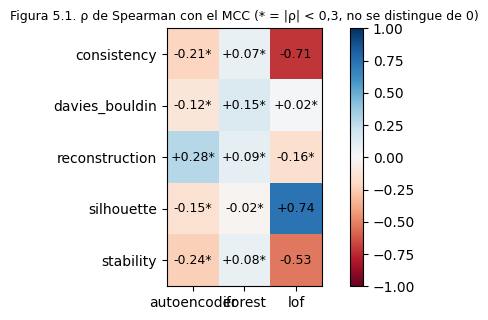

Fuente: outputs_v2\results\diagnose_objectives_summary.json (sha256 90d515cd9c3e…, 2026-11-13 18:43) | código: 2_diagnose.main (--n 40, --seed 0)


In [15]:
if hay(RES / "diagnose_objectives_summary.json", que="diagnóstico"):
    dg = pd.DataFrame(common.load_json(RES / "diagnose_objectives_summary.json"))
    piv = dg.pivot(index="metric", columns="detector", values="rho_mcc")
    display(dg.pivot(index="metric", columns="detector", values=["rho_mcc", "rho_auroc"]).round(3))
    fig, ax = plt.subplots(figsize=(6, 3.3))
    im = ax.imshow(piv.values, cmap="RdBu", vmin=-1, vmax=1)
    ax.set_xticks(range(piv.shape[1]), piv.columns); ax.set_yticks(range(piv.shape[0]), piv.index)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            v = piv.values[i, j]
            if np.isfinite(v): ax.text(j, i, f"{v:+.2f}" + ("" if abs(v) >= 0.3 else "*"), ha="center", va="center", fontsize=9)
    ax.set_title("Figura 5.1. ρ de Spearman con el MCC (* = |ρ| < 0,3, no se distingue de 0)", fontsize=9)
    plt.colorbar(im, ax=ax); plt.tight_layout(); plt.show()
    fuente(RES / "diagnose_objectives_summary.json", "2_diagnose.main (--n 40, --seed 0)")

---
# 7. La búsqueda de hiperparámetros *(Memoria 3.2.4 a 3.2.8, Tablas 3.5 y 3.6)*
Uso Optuna con el muestreador TPE: 100 intentos por búsqueda, cinco semillas y sin poda temprana. Un intento se
descarta si su latencia en el PC pasa de 20 ms (el límite de 100 ms dividido por 5, que es cuánto más lenta supongo
que es la Raspberry) o si el modelo pesa más de 50 MB. De cada búsqueda guardo las cinco mejores configuraciones.

In [16]:
# Leo los archivos de cada búsqueda por separado: all_studies.json es un resumen que se reescribe en cada lote
archivos = sorted((OUT / "optuna").glob("*_seed*.json"))
if not archivos:
    hay(OUT / "optuna", que="búsqueda con Optuna")
else:
    studies = pd.DataFrame([{k: v for k, v in common.load_json(f).items() if k not in ("top_k", "trials")} for f in archivos])
    res6 = (studies.groupby(["detector", "metric"])
            .agg(búsquedas=("seed", "count"), completos=("n_completed", "sum"), descartados=("n_pruned", "sum"),
                 mejor_valor_medio=("best_value", "mean"), minutos=("elapsed_s", lambda x: round(x.sum() / 60, 1))))
    display(res6.round(4))
    print(f"Total: {len(studies)} de 60 búsquedas, {int(studies.n_completed.sum()):,} intentos completos, "
          f"{int(studies.n_pruned.sum())} descartados por los límites del borde, {studies.elapsed_s.sum() / 3600:.1f} h de cómputo.")
    fuente(OUT / "optuna", "3_optimize.run_study (optuna/<detector>_<criterio>_seed<s>.json)",
           f"n_trials={cfg['optimization']['n_trials']}, seeds={cfg['optimization']['seeds']}, top_k={cfg['optimization']['top_k']}")

búsquedas  completos  descartados  mejor_valor_medio  minutos
detector    metric                                                                       
autoencoder reconstruction          5        500            0             0.0006   1060.3
            stability               5        500            0             0.9801     13.0
iforest     davies_bouldin          5        414           86             0.3430     12.8
            oracle                  1        100            0             0.3742      1.9
            silhouette              5        411           89             0.6799     13.7
lof         davies_bouldin          5        500            0             1.5485      7.4
            silhouette              5        500            0             0.9095     19.5

Total: 31 de 60 búsquedas, 2,925 intentos completos, 175 descartados por los límites del borde, 18.8 h de cómputo.
Fuente: outputs_v2\optuna (sha256 -…, 2026-11-14 13:38) | código: 3_optimize.run_study (optuna/<detector>_<criterio>_seed<s>.json) | config: n_trials=100, seeds=[42, 43, 44, 45, 46], top_k=5


In [17]:
if hay(MOD / "index.json", que="modelos guardados"):
    idx = pd.DataFrame(common.load_json(MOD / "index.json"))
    print("Modelos guardados (models/index.json):")
    display(idx.groupby(["config", "detector"]).size().unstack(fill_value=0))
    # hiperparámetros elegidos (rango 0) por detector y criterio, semilla 42
    r0 = idx[idx["rank"] == 0].copy()
    r0["params"] = r0["params"].map(lambda p: {k: (round(v, 4) if isinstance(v, float) else v) for k, v in p.items() if k not in ("random_state", "backend")})
    display(r0[r0.seed == 42][["detector", "metric", "config", "params", "latency_dev_ms", "model_kb"]].sort_values(["detector", "config"]))
    fuente(MOD / "index.json", "3_optimize.run_study + build_baseline (semilla 42)")

Modelos guardados (models/index.json):


detector,autoencoder,iforest,lof
config,,,
optimizada,50,50,50
oraculo,0,5,0


,detector,metric,config,params,latency_dev_ms,model_kb
100,autoencoder,reconstruction,optimizada,"{'n_layers': 1, 'units': 115, 'latent_dim': 16...",0.03010,63.176758
125,autoencoder,stability,optimizada,"{'n_layers': 1, 'units': 8, 'latent_dim': 2, '...",0.11095,14.598633
0,iforest,silhouette,optimizada,"{'max_samples': 3707, 'n_estimators': 50, 'max...",8.12370,2316.194336
25,iforest,davies_bouldin,optimizada,"{'max_samples': 2343, 'n_estimators': 50, 'max...",8.52040,1998.510742
150,iforest,oracle,oraculo,"{'max_samples': 136, 'n_estimators': 125, 'max...",5.37795,971.495117
50,lof,silhouette,optimizada,"{'n_neighbors': 7, 'leaf_size': 17, 'metric': ...",1.44625,1925.999023
75,lof,davies_bouldin,optimizada,"{'n_neighbors': 60, 'leaf_size': 25, 'metric':...",1.15915,3996.311523


Fuente: outputs_v2\models\index.json (sha256 568fd27d24a4…, 2026-11-14 13:38) | código: 3_optimize.run_study + build_baseline (semilla 42)


### ¿La búsqueda se puede reproducir?
No exactamente, aunque todas las semillas estén fijas. El motivo es el descarte por latencia: depende del tiempo que
se mide en el PC, y ese tiempo cambia según lo cargado que esté el equipo. Un intento que queda cerca de los 20 ms
puede descartarse en una corrida y no en otra, y desde ahí TPE sigue un camino distinto. En la v1 hubo 97 descartes,
49 de ellos en `iforest/davies_bouldin/seed45`. Cuando repetí la búsqueda iforest/silhouette/42 obtuve 0,7602
contra 0,7611 de la guardada: muy cerca, pero no igual.

Por eso, desde la v2 cada búsqueda guarda el historial completo de sus intentos (campo `trials` del JSON), para
poder revisar después qué se descartó y por qué. Con `REPETIR_UNA_BUSQUEDA = True` la celda siguiente repite una
búsqueda y la compara con la guardada.

In [18]:
g_path = OUT / "optuna/iforest_silhouette_seed42.json"
if not REPETIR_UNA_BUSQUEDA:
    print("REPETIR_UNA_BUSQUEDA = False: me la salto (tarda unos 2 minutos).")
elif hay(g_path, que="búsqueda guardada para comparar"):
    Xtr, _ = common.load_split(cfg, "train"); Xv, _ = common.load_split(cfg, "val"); cal, obj = common.split_val(Xv, cfg)
    tmp = Path(tempfile.mkdtemp()); cfg2 = common.deep_merge(cfg, {"paths": {"outputs_dir": str(tmp)}})
    r = opt.run_study(cfg2, "iforest", "silhouette", 42, cfg["optimization"]["n_trials"], {"train": Xtr, "calib": cal, "obj": obj})
    g = common.load_json(g_path)
    display(pd.DataFrame({"guardado": [g["best_value"], g["n_pruned"], g["best_params"]],
                          "repetido": [r["best_value"], r["n_pruned"], r["best_params"]]}, index=["mejor valor", "descartados", "parámetros"]))

REPETIR_UNA_BUSQUEDA = False: me la salto (tarda unos 2 minutos).


---
# 8. Medición en la Raspberry Pi 5 *(Memoria 3.2.8, etapa 2)*: pendiente
Esta parte todavía falta. Hay que correr `src/4_edge_benchmark.py` en la Raspberry con la carpeta de modelos y el
archivo `edge_sample.csv` de las particiones. Mientras tanto, la única referencia de costo que tengo es la latencia
mediana medida en el PC durante la búsqueda, que no reemplaza la medición en el dispositivo.

In [19]:
ep = RES / "edge_benchmark.csv"
if ep.exists():
    display(pd.read_csv(ep).head()); fuente(ep, "4_edge_benchmark.main")
elif hay(MOD / "index.json", que="modelos para medir"):
    idx = pd.DataFrame(common.load_json(MOD / "index.json"))
    lat = idx.groupby(["detector", "config"])[["latency_dev_ms", "model_kb"]].median().round(3)
    print("Todavía no existe edge_benchmark.csv. Referencia provisional: PC, mediana de 50 inferencias.")
    display(lat); fuente(MOD / "index.json", "3_optimize.measure_latency_ms (PC de desarrollo)")

Todavía no existe edge_benchmark.csv. Referencia provisional: PC, mediana de 50 inferencias.


latency_dev_ms  model_kb
detector    config                              
autoencoder optimizada           0.033    47.250
iforest     optimizada           8.548  2540.987
            oraculo              9.576  1497.766
lof         optimizada           1.179  2550.999

Fuente: outputs_v2\models\index.json (sha256 568fd27d24a4…, 2026-11-14 13:38) | código: 3_optimize.measure_latency_ms (PC de desarrollo)


---
# 9. Evaluación final en `test_final` *(Memoria 3.2.9)*
Primero reviso con SHA-256 que las dos mitades de la prueba no hayan cambiado. Esto solo calcula la huella del
archivo, no lee las etiquetas. Después resumo lo que guardó `5_evaluate.py`. El cuaderno no vuelve a abrir
`test_final` a menos que active `VERIFICAR_EVALUACION`. Mientras falte la medición en la Raspberry, el modelo
elegido de cada búsqueda es el de rango 0.

In [20]:
ev.verify_integrity(cfg)
fe = pd.read_csv(RES / "final_evaluation.csv") if hay(RES / "final_evaluation.csv", que="evaluación final") else None
if fe is not None and VERIFICAR_EVALUACION:   # reevalúa los modelos de la semilla 42 y compara con lo guardado
    X, y, _ = common.load_labeled(cfg, "test_final")
    elegidos = [e for e in ev.select_entries(common.load_json(MOD / "index.json"), None) if e["seed"] == 42]
    comp = []
    for e in elegidos:
        m, _, _ = ev.evaluate_entry(e, MOD, X, y, cfg)
        g = fe[(fe.detector == e["detector"]) & (fe.metric == e["metric"]) & (fe.seed == 42) & (fe.config == e["config"])]
        comp.append({"detector": e["detector"], "criterio": e["metric"], "MCC guardado": g.MCC.iloc[0], "MCC recalculado": m["MCC"]})
    comp = pd.DataFrame(comp); comp["¿idéntico?"] = np.isclose(comp["MCC guardado"], comp["MCC recalculado"], atol=1e-12)
    display(comp.round(6)); print("Todos idénticos:", bool(comp["¿idéntico?"].all()))
elif fe is not None:
    print("VERIFICAR_EVALUACION = False: no vuelvo a leer las etiquetas de test_final.")
    if VERSION == "v1":
        print("Última verificación (13-11-2026): el MCC recalculado es idéntico al guardado en los 15 modelos de la semilla 42.")

Integridad de los bloques de prueba verificada (SHA-256).
Pendiente: evaluación final. Todavía no existe: outputs_v2\results\final_evaluation.csv


### Tabla 8.1: detección por detector y criterio (media ± desviación en 5 semillas)

In [21]:
col = {"linea_base": "#999999", "optimizada": "#4C72B0", "oraculo": "#DD8452"}
if fe is not None:
    d = fe[fe.config != "linea_base_nativa"]
    agg = d.groupby(["detector", "config", "metric"]).agg(
        MCC=("MCC", "mean"), MCC_sd=("MCC", "std"), MCC_pi10=("MCC_pi10", "mean"), AUROC=("AUROC", "mean"),
        AUPRC=("AUPRC", "mean"), Recall=("Recall", "mean"), FPR=("FPR", "mean"), semillas=("seed", "count")).round(3)
    orden = {"linea_base": 0, "optimizada": 1, "oraculo": 2}
    agg = agg.reset_index().sort_values(["detector", "config"], key=lambda s: s.map(orden).fillna(s)).set_index(["detector", "config", "metric"])
    display(agg)
    fuente(RES / "final_evaluation.csv", "5_evaluate.evaluate_entry",
           f"q={cfg['threshold']['q']}, report_prevalences={cfg['split']['report_prevalences']}")

    fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
    for ax, (det, g) in zip(axs, agg.reset_index().groupby("detector")):
        ax.bar(range(len(g)), g.MCC, yerr=g.MCC_sd.fillna(0), color=[col[c] for c in g.config], capsize=3)
        ax.set_xticks(range(len(g)), g.metric, rotation=35, ha="right", fontsize=8); ax.set_title(det); ax.axhline(0, color="k", lw=.5)
    axs[0].set_ylabel("MCC en test_final")
    for c, k in col.items(): axs[2].bar(0, 0, color=k, label=c)
    axs[2].legend(fontsize=8); fig.suptitle("Figura 8.1. MCC por escenario (media ± d.e., 5 semillas)"); plt.tight_layout(); plt.show()
    fuente(RES / "final_evaluation.csv", "5_evaluate.main")

### Tabla 8.2: mejor criterio sin etiquetas frente a la línea base y al oráculo
Comparo semilla por semilla la configuración optimizada con la línea base de la misma semilla. Con las cinco
diferencias de MCC calculo el promedio (Δ) y su error estándar (EE). Digo que un criterio mejora la línea base solo
si Δ − 2EE > 0, y que la empeora si Δ + 2EE < 0; en otro caso, la mantiene (memoria 3.2.9).

In [22]:
if hay(RES / "balance.csv", RES / "balance_por_metrica.csv", que="comparación con la línea base"):
    bal = pd.read_csv(RES / "balance.csv"); display(bal)
    fuente(RES / "balance.csv", "5_evaluate.summarize")
    bpm = pd.read_csv(RES / "balance_por_metrica.csv")
    display(bpm[["detector", "metric", "config", "mcc_medio", "mcc_std", "delta_mcc", "delta_se", "dist_oraculo"]].round(4))
    fuente(RES / "balance_por_metrica.csv", "5_evaluate.summarize")

Pendiente: comparación con la línea base. Todavía no existe: outputs_v2\results\balance.csv, outputs_v2\results\balance_por_metrica.csv


### ¿Se cumple la hipótesis?
Mi hipótesis es que la mejor métrica depende del detector y que, con la métrica adecuada, el detector no queda peor
que con sus valores por defecto. La doy por respaldada solo si se cumplen las tres condiciones de la sección 3.2.9.

In [23]:
if hay(RES / "hypothesis_check.json", que="contraste de la hipótesis"):
    hyp = common.load_json(RES / "hypothesis_check.json")
    display(pd.DataFrame(hyp["por_detector"]).T)
    c1 = all(v["estado_vs_base"] != "empeora" for v in hyp["por_detector"].values())
    c3 = all(v["separable"] for v in hyp["por_detector"].values())
    print(f"(1) ninguna métrica ganadora empeora la línea base: {c1}")
    print(f"(2) las ganadoras difieren entre detectores: {hyp['difieren']}  {hyp['metricas_ganadoras']}")
    print(f"(3) en todos, el margen sobre la segunda supera la dispersión entre semillas: {c3}")
    print(f"=> Hipótesis respaldada: {hyp['hipotesis_soportada']}  (provisional mientras falte la medición en la Raspberry)")
    fuente(RES / "hypothesis_check.json", "5_evaluate.summarize")

Pendiente: contraste de la hipótesis. Todavía no existe: outputs_v2\results\hypothesis_check.json


### Tabla 8.3: recall por tipo de ataque (mejor criterio y línea base)

In [24]:
if hay(RES / "recall_por_ataque.csv", RES / "balance.csv", que="recall por tipo de ataque"):
    bal = pd.read_csv(RES / "balance.csv")
    rpa = pd.read_csv(RES / "recall_por_ataque.csv")
    sel = pd.concat([rpa[(rpa.detector == b.detector) & (rpa.metric.isin([b.mejor_metrica, "por_defecto"]))] for b in bal.itertuples()])
    display(sel.pivot_table(index=["detector", "metric"], columns="attack_type", values="recall").round(2))
    fuente(RES / "recall_por_ataque.csv", "5_evaluate.main")

Pendiente: recall por tipo de ataque. Todavía no existe: outputs_v2\results\recall_por_ataque.csv, outputs_v2\results\balance.csv


### Tabla 8.4: sensibilidad al umbral
Es solo descriptiva: muestra cómo cambiaría el MCC con otros percentiles, pero no la uso para elegir nada.

In [25]:
if fe is not None:
    qcols = [c for c in fe.columns if c.startswith("MCC_q")]
    display(d.groupby(["detector", "config", "metric"])[qcols].mean().round(3))
    fuente(RES / "final_evaluation.csv", "5_evaluate.evaluate_entry", f"sensitivity_q={cfg['threshold']['sensitivity_q']}")

### Figura 8.2: frente de Pareto entre MCC y latencia
Es provisional, porque usa la latencia medida en el PC y no la de la Raspberry.

In [26]:
if hay(RES / "pareto_mcc_latencia.csv", que="frente de Pareto"):
    par = pd.read_csv(RES / "pareto_mcc_latencia.csv")
    fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
    for ax, (det, g) in zip(axs, par.groupby("detector")):
        for c, k in col.items():
            gg = g[g.config == c]; ax.scatter(gg.latencia_ms, gg.MCC, c=k, s=18, label=c, alpha=.8)
        f = g[g.en_frente].sort_values("latencia_ms"); ax.plot(f.latencia_ms, f.MCC, "k--", lw=1)
        ax.set_xscale("log"); ax.set_title(det); ax.set_xlabel(f"latencia (ms, {g.fuente_latencia.iloc[0]})")
    axs[0].set_ylabel("MCC"); axs[0].legend(fontsize=7); plt.tight_layout(); plt.show()
    fuente(RES / "pareto_mcc_latencia.csv", "5_evaluate.pareto_front")

Pendiente: frente de Pareto. Todavía no existe: outputs_v2\results\pareto_mcc_latencia.csv


---
# 10. Tablas para la memoria
Las genera `src/6_report.py` en la carpeta `tables/` de las salidas, y las incluyo en la memoria con `\input{}`.
Así ningún número se copia a mano.

In [27]:
tex = sorted((OUT / "tables").glob("*.tex"))
if not tex:
    hay(OUT / "tables", que="tablas LaTeX")
for f in tex:
    txt = f.read_text(encoding="utf-8")
    print(f"{f.name:28s} {'PENDIENTE' if '[Pendiente]' in txt else 'con datos'}  (sha256 {sha(f)}…)")

Pendiente: tablas LaTeX. Todavía no existe: outputs_v2\tables


---
# 11. Resumen
Estado al 13-11-2026.

**Lo que ya está y comprobé**
- Las particiones de la v2 se reproducen byte a byte (sección 4) y casi no quedan flujos repetidos entre bloques:
  0,5 % de la validación, 0,2 % de los normales de `test_final` y 0,1 % entre las dos mitades de la prueba. En la v1
  eran más de la mitad.
- El diagnóstico de las funciones objetivo de la v2 (sección 6).
- Con la v1 comprobé que la evaluación es exactamente reproducible: el MCC recalculado coincide con el guardado.

**Lo que está corriendo**
- Las 60 búsquedas con Optuna de la v2 y, cuando terminen, la evaluación final y las tablas.

**Lo que falta**
- La medición en la Raspberry Pi 5 (`4_edge_benchmark.py`) y, con ella, volver a correr `5_evaluate.py` y
  `6_report.py`. Hasta entonces, la elección de cada modelo, el frente de Pareto y el contraste de la hipótesis
  son provisionales.

**Lo que me gustaría conversar**
1. La búsqueda solo se reproduce de forma aproximada, por el descarte basado en la latencia medida (sección 7). Quiero
   saber si basta con declararlo en 3.2.11 y guardar el historial de intentos, o si conviene medir la latencia de
   otra forma (por ejemplo, con un costo estimado en vez del tiempo real).